In [5]:
import sys
import os
import docx
import re
sys.path.append(os.path.abspath('../../'))  # Add root to path to import algo
from algo.evaluate import evaluate_comparisons
from algo.comparison import compare_tokens
from algo.structures import Weights
import json
import pandas as pd

### Функция, которая переводит список WordOp в json 

In [88]:
from __future__ import annotations

import json
from typing import Any, Dict, List, Sequence, Union

from algo.structures import WordOp


def word_ops_to_evaluate_input(
    ops: Sequence[WordOp],
    *,
    as_json_string: bool = False,
) -> Union[List[Dict[str, Any]], str]:
    """
    Список WordOp → данные для evaluate_comparisons (список dict).
    По умолчанию возвращает list[dict] — его можно сразу передать как первый или второй аргумент.
    Если as_json_string=True — JSON-строка (для записи в файл); перед вызовом evaluate_comparisons сделайте json.loads.
    """
    out: List[Dict[str, Any]] = []
    for op in ops:
        ot = op.op_type.value if hasattr(op.op_type, "value") else str(op.op_type)
        out.append(
            {
                "op_type": ot,
                "base_token": op.base_token,
                "other_token": op.other_token,
            }
        )
    if as_json_string:
        return json.dumps(out, ensure_ascii=False)
    return out

In [89]:
def get_json_comparison(t1='M10.docx', t2='МИД181.docx', algo_name='levenshtein_v2', algo_params=Weights(1, 1, 1, 1, 1, 1)):
    def read_docx(path):
        doc = docx.Document(path)
        return " ".join([p.text for p in doc.paragraphs])

    def tokenize(text):
        return re.findall(r'\S+', text)

    # 1. Читаем тексты
    t1_read = read_docx(f'data_m10/test/{t1}')
    t2_read = read_docx(f'data_m10/test/{t2}')

    # 2. Токенизируем
    t1_tokens = tokenize(t1_read)
    t2_tokens = tokenize(t2_read)

    # 3. Сравниваем (можно выбрать "myers", "levenshtein", "levenshtein_nested", levenshtein_v2)
    return word_ops_to_evaluate_input(compare_tokens(t1_tokens, t2_tokens, algo_params, algorithm=algo_name))

### Конкретные результаты

In [90]:
test_text = 'M10'
correct_text = 'МИД181'

test = get_json_comparison(
    t1=f'{test_text}.docx',
    t2=f'{correct_text}.docx',
    algo_name='levenshtein',
    algo_params=Weights(1, 1, 1, 100, 1, 1)
)
with open(f'/Users/ehlamkin/Desktop/nir_2026_v2/testing/quality/data_m10/correct/{test_text}_{correct_text}_correct.json', 'r', encoding='utf-8') as f:
    correct = json.load(f)

In [91]:
results = evaluate_comparisons(test, correct)

print("Recall:", results['recall'])
print("Precision:", results['precision'])
print("F1 Score:", results['f1_score'])
print("\n--- Recall Elements ---")
for el in results['recall_elements']:
    print(el)
    
print("\n--- Precision Elements ---")
for el in results['precision_elements']:
    print(el)

Recall: 0.896551724137931
Precision: 0.8688946015424165
F1 Score: 0.8825065274151437

--- Recall Elements ---
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'възвеселе'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'высоты'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'ѹтвержⷣенїа'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'оцѣщеⷩ\ue003а'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'зрⷦ\ue003'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'нб҃сї'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'вїдѣнїеⷨ'}
{'op1': 'delete', 'op2': 'delete', 'other_token1': None, 'other_token2': None, 'base_token': 'сл҃вы'}
{'op1': 'delete', 'op2': 'delete', 'other_token1

### Оптимизация

In [92]:
import time

def optimize_weights(algo_name='levenshtein_v2', diapazon=4):

    texts = {
        'МИД181': [], 
        'GB': [], 
        'GB2': [], 
        'IV13': [], 
        'IV605': [], 
        'MN': [], 
        'P78': [], 
        'P81': [], 
        'TB': [], 
        'Tr730': [], 
        'U3': []
    }

    for text in texts:
        with open(f'/Users/ehlamkin/Desktop/nir_2026_v2/testing/quality/data_m10/correct/M10_{text}_correct.json', 'r', encoding='utf-8') as f:
            correct = json.load(f)
        for w1 in range(1, diapazon + 1):
            for w2 in range(1, diapazon + 1):
                for w3 in range(1, diapazon + 1):
                    start_time = time.perf_counter() * 1000  # время в миллисекундах

                    test = get_json_comparison(
                        t1=f'M10.docx',
                        t2=f'{text}.docx',
                        algo_name=algo_name,
                        algo_params=Weights(w1, w2, w3, 1, 1, 1)
                    )

                    end_time = time.perf_counter() * 1000
                    execution_time_ms = end_time - start_time

                    results = evaluate_comparisons(test, correct)
                    texts[text].append([[w1, w2, w3], results['recall'], results['precision'], results['f1_score'], execution_time_ms])


    # Преобразуем вложенный словарь texts в плоский список строк для df
    rows = []
    for text, results in texts.items():
        for entry in results:
            params, recall, precision, f1, execution_time_ms = entry
            rows.append({
                'Text': text,
                'Index': results.index(entry),
                'w1': params[0],
                'w2': params[1],
                'w3': params[2],
                'Recall': recall,
                'Precision': precision,
                'F1 Score': f1,
                'time ms': execution_time_ms
            })

    df = pd.DataFrame(rows)

    return df

In [93]:
# Группировка по текстам и вывод статистик по каждому тексту
def texts_metrics(df):
    grouped = df.groupby('Text')

    for text, group in grouped:
        f1_mean = group['F1 Score'].mean()
        f1_median = group['F1 Score'].median()
        f1_min = group['F1 Score'].min()
        f1_max = group['F1 Score'].max()
        
        max_f1_rows = group[group['F1 Score'] == f1_max]
        max_f1_row = max_f1_rows.iloc[0]
        w1_max, w2_max, w3_max = max_f1_row['w1'], max_f1_row['w2'], max_f1_row['w3']
        
        print(f"Текст: {text}")
        print(f"  Среднее значение F1 Score: {f1_mean:.6f}")
        print(f"  Медианное значение F1 Score: {f1_median:.6f}")
        print(f"  Минимальное значение F1 Score: {f1_min:.6f}")
        print(f"  Максимальное значение F1 Score: {f1_max:.6f}")
        print(f"  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1={w1_max}, w2={w2_max}, w3={w3_max}\n")

In [94]:
def best_params(df):

    # Группировка по тройкам весов (w1, w2, w3) и расчет статистик для каждой метрики
    weight_grouped = df.groupby(['w1', 'w2', 'w3'])

    stats_rows = []
    stats_rows_full= []

    for weights, group in weight_grouped:
        w1, w2, w3 = weights
        recall_min = group['Recall'].min()
        recall_max = group['Recall'].max()
        recall_mean = group['Recall'].mean()
        
        precision_min = group['Precision'].min()
        precision_max = group['Precision'].max()
        precision_mean = group['Precision'].mean()
        
        f1_min = group['F1 Score'].min()
        f1_max = group['F1 Score'].max()
        f1_mean = group['F1 Score'].mean()

        time_min = group['time ms'].min()
        time_max = group['time ms'].max()
        time_mean = group['time ms'].mean()
        
        stats_rows.append({
            'w1': w1,
            'w2': w2,
            'w3': w3,
            # 'Recall_min': recall_min,
            # 'Recall_max': recall_max,
            'Recall_mean': recall_mean,
            # 'Precision_min': precision_min,
            # 'Precision_max': precision_max,
            'Precision_mean': precision_mean,
            # 'F1_min': f1_min,
            # 'F1_max': f1_max,
            'F1_mean': f1_mean,
            # 'Time_min_ms': time_min,
            # 'Time_max_ms': time_max,
            'Time_mean_ms': time_mean    })

        stats_rows_full.append({
            'w1': w1,
            'w2': w2,
            'w3': w3,
            'Recall_min': recall_min,
            'Recall_max': recall_max,
            'Recall_mean': recall_mean,
            'Precision_min': precision_min,
            'Precision_max': precision_max,
            'Precision_mean': precision_mean,
            'F1_min': f1_min,
            'F1_max': f1_max,
            'F1_mean': f1_mean,
            'Time_min_ms': time_min,
            'Time_max_ms': time_max,
            'Time_mean_ms': time_mean    })

    weights_stats_df = pd.DataFrame(stats_rows)
    weights_stats_df_full = pd.DataFrame(stats_rows_full)

    # Для каждой метрики найдем строку с максимальным значением

    max_recall_row = weights_stats_df.loc[weights_stats_df['Recall_mean'].idxmax()]
    max_precision_row = weights_stats_df.loc[weights_stats_df['Precision_mean'].idxmax()]
    max_f1_row = weights_stats_df.loc[weights_stats_df['F1_mean'].idxmax()]
    max_time_row = weights_stats_df.loc[weights_stats_df['Time_mean_ms'].idxmax()]

    print("Веса с максимальным Recall_mean: (w1, w2, w3) =", 
        (max_recall_row['w1'], max_recall_row['w2'], max_recall_row['w3']), 
        "->", max_recall_row['Recall_mean'])

    print("Веса с максимальным Precision_mean: (w1, w2, w3) =", 
        (max_precision_row['w1'], max_precision_row['w2'], max_precision_row['w3']), 
        "->", max_precision_row['Precision_mean'])

    print("Веса с максимальным F1_mean: (w1, w2, w3) =", 
        (max_f1_row['w1'], max_f1_row['w2'], max_f1_row['w3']), 
        "->", max_f1_row['F1_mean'])

    print("Веса с максимальным Time_mean_ms: (w1, w2, w3) =", 
        (max_time_row['w1'], max_time_row['w2'], max_time_row['w3']), 
        "->", max_time_row['Time_mean_ms'])
        
    return weights_stats_df, weights_stats_df_full


In [95]:
def plot_metrics(weights_stats_df_full):

    import matplotlib.pyplot as plt

    # Для каждого показателя построим график: среднее (линия) и коридор min-max (заливка)

    metrics = [
        ("Recall", "Recall_mean", "Recall_min", "Recall_max"),
        ("Precision", "Precision_mean", "Precision_min", "Precision_max"),
        ("F1 Score", "F1_mean", "F1_min", "F1_max"),
        ("Time, ms", "Time_mean_ms", "Time_min_ms", "Time_max_ms"),
    ]

    fig, axes = plt.subplots(4, 1, figsize=(14, 20))

    # Подписи для оси X — тройки весов
    weight_labels = weights_stats_df_full.apply(
        lambda row: f"({int(row['w1'])},{int(row['w2'])},{int(row['w3'])})", axis=1)

    x = range(len(weights_stats_df_full))

    for ax, (title, mean_col, min_col, max_col) in zip(axes, metrics):
        mean = weights_stats_df_full[mean_col]
        min_ = weights_stats_df_full[min_col]
        max_ = weights_stats_df_full[max_col]

        ax.plot(x, mean, label=f"{title} (mean)", color='b')
        ax.fill_between(x, min_, max_, color='b', alpha=0.2, label=f"{title} min-max corridor")

        # Добавляем красную точку с максимальным средним значением
        max_mean_idx = mean.idxmax()
        ax.plot(
            max_mean_idx,
            mean[max_mean_idx],
            'ro',
            markersize=8,
            label=f"Максимум {title} mean"
        )

        ax.set_xlabel("Веса (w1, w2, w3)")
        ax.set_ylabel(title)
        ax.set_title(f"{title}: mean and min-max corridor")
        ax.legend()
        ax.grid(True)
        # Показываем тройки весов на оси x
        ax.set_xticks(x)
        ax.set_xticklabels(weight_labels, rotation=90, fontsize=8)

    plt.tight_layout()
    plt.show()

# Global Options 

In [96]:
DIAPAZON = 6

# Lev

Текст: GB
  Среднее значение F1 Score: 0.972138
  Медианное значение F1 Score: 0.980663
  Минимальное значение F1 Score: 0.888594
  Максимальное значение F1 Score: 0.980663
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1, w2=1, w3=1

Текст: GB2
  Среднее значение F1 Score: 0.983848
  Медианное значение F1 Score: 0.994444
  Минимальное значение F1 Score: 0.880000
  Максимальное значение F1 Score: 0.994444
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1, w2=1, w3=1

Текст: IV13
  Среднее значение F1 Score: 0.979965
  Медианное значение F1 Score: 0.986150
  Минимальное значение F1 Score: 0.919355
  Максимальное значение F1 Score: 0.986150
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1, w2=1, w3=1

Текст: IV605
  Среднее значение F1 Score: 0.979890
  Медианное значение F1 Score: 0.986111
  Минимальное значение F1 Score: 0.918919
  Максимальное значение F1 Score: 0.986111
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1

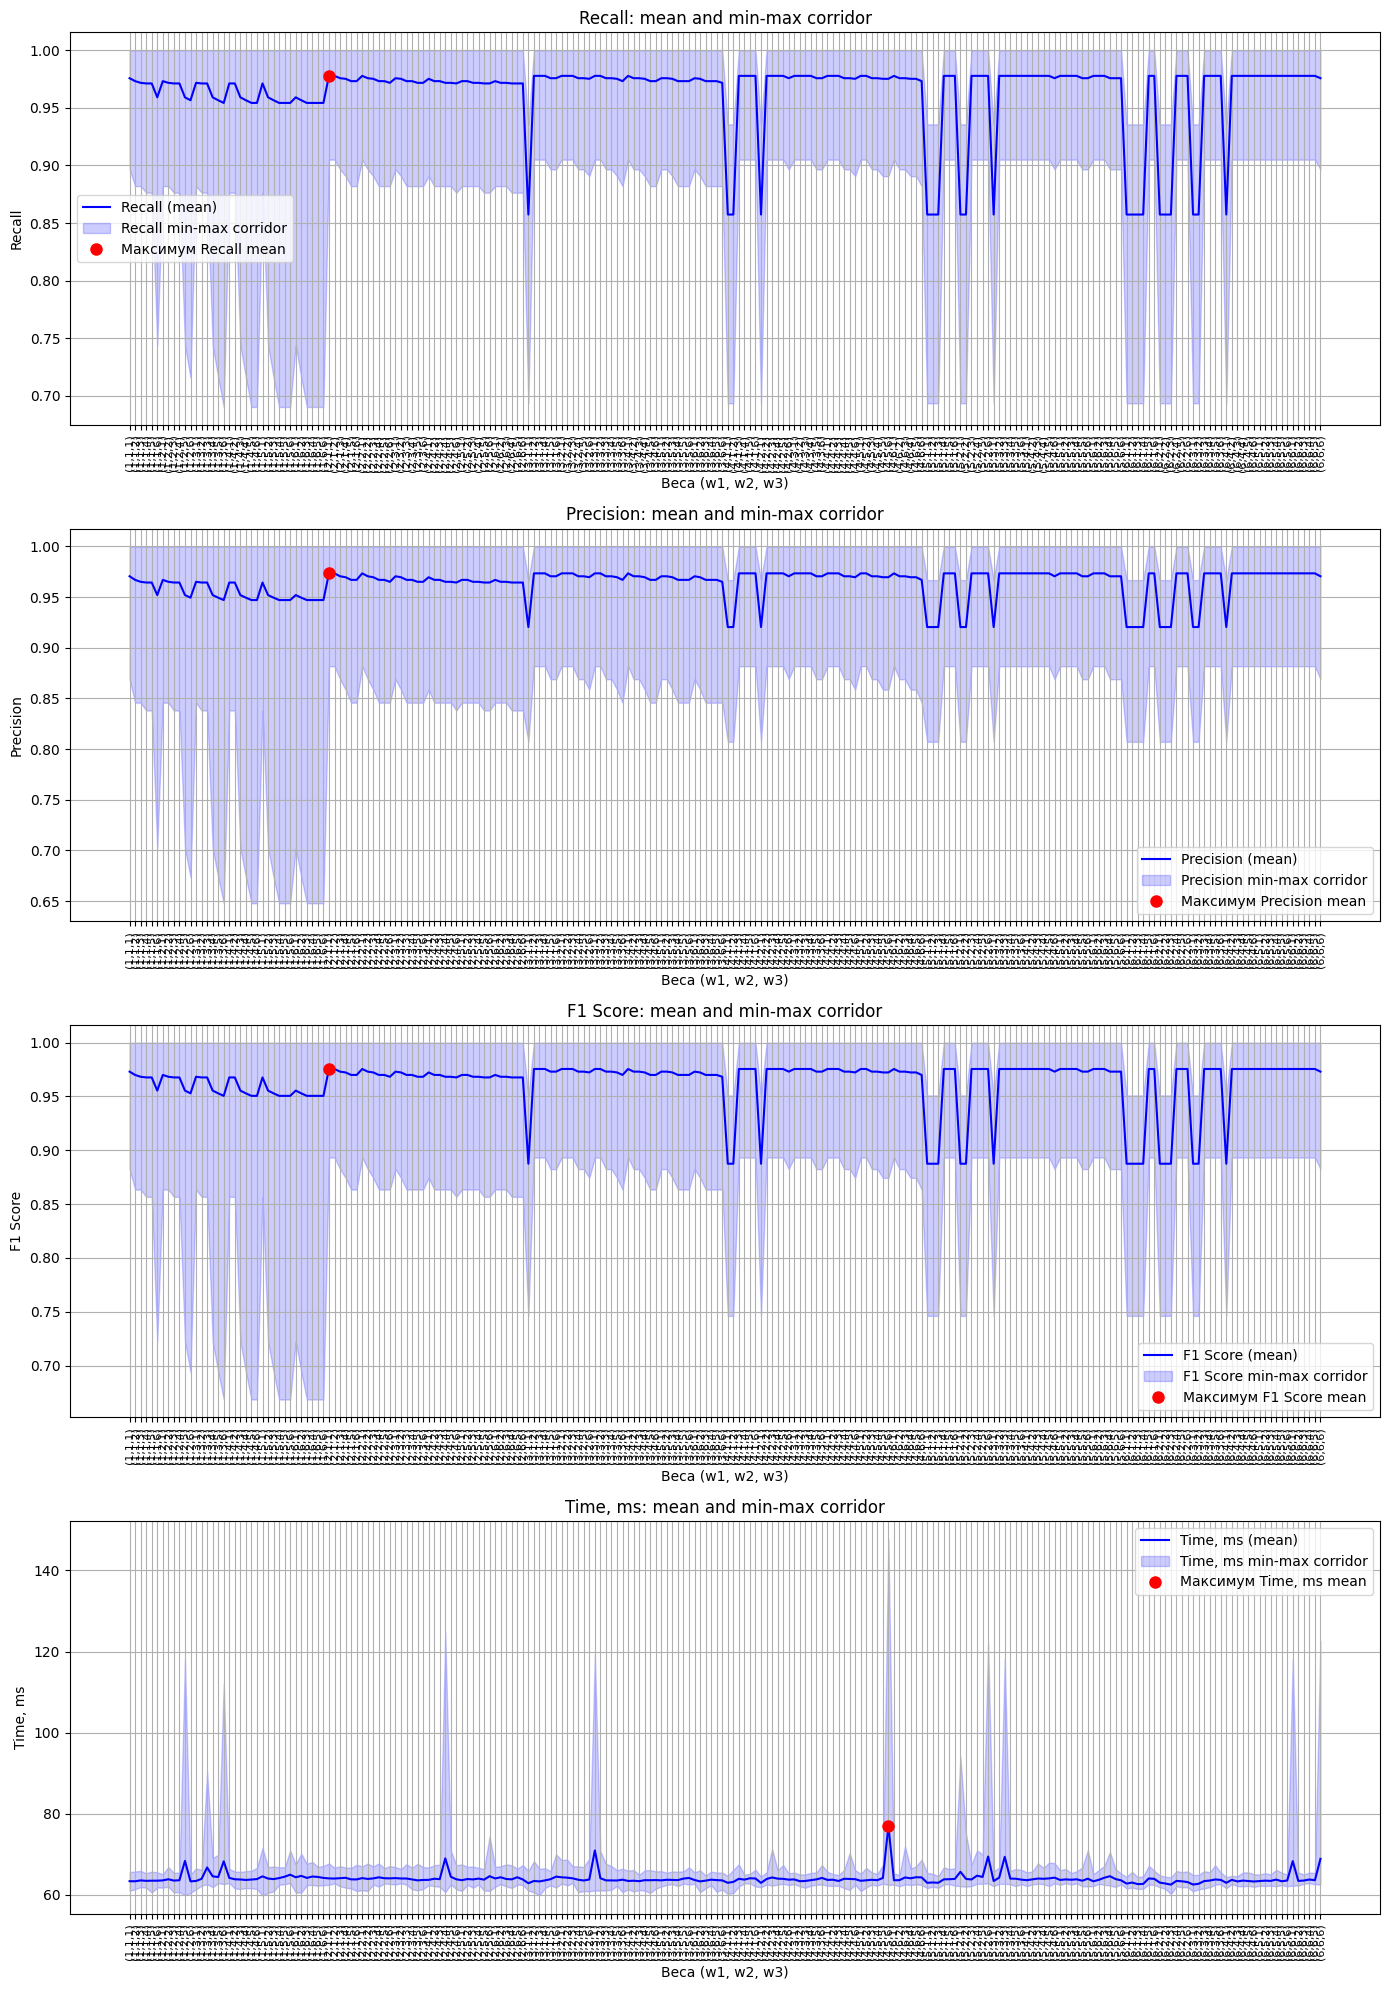

In [97]:
df_lev = optimize_weights(algo_name='levenshtein', diapazon=DIAPAZON)
texts_metrics(df_lev)
_, weights_stats_df_full_df_lev = best_params(df_lev)
weights_stats_df_full_df_lev.head()
plot_metrics(weights_stats_df_full_df_lev)

# Lev Nested

Текст: GB
  Среднее значение F1 Score: 0.986314
  Медианное значение F1 Score: 0.986188
  Минимальное значение F1 Score: 0.935135
  Максимальное значение F1 Score: 0.990345
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=2, w2=1, w3=1

Текст: GB2
  Среднее значение F1 Score: 0.999104
  Медианное значение F1 Score: 1.000000
  Минимальное значение F1 Score: 0.938776
  Максимальное значение F1 Score: 1.000000
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1, w2=1, w3=1

Текст: IV13
  Среднее значение F1 Score: 0.986028
  Медианное значение F1 Score: 0.986150
  Минимальное значение F1 Score: 0.946939
  Максимальное значение F1 Score: 0.990318
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=2, w2=1, w3=1

Текст: IV605
  Среднее значение F1 Score: 0.994631
  Медианное значение F1 Score: 0.994444
  Минимальное значение F1 Score: 0.954856
  Максимальное значение F1 Score: 1.000000
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1

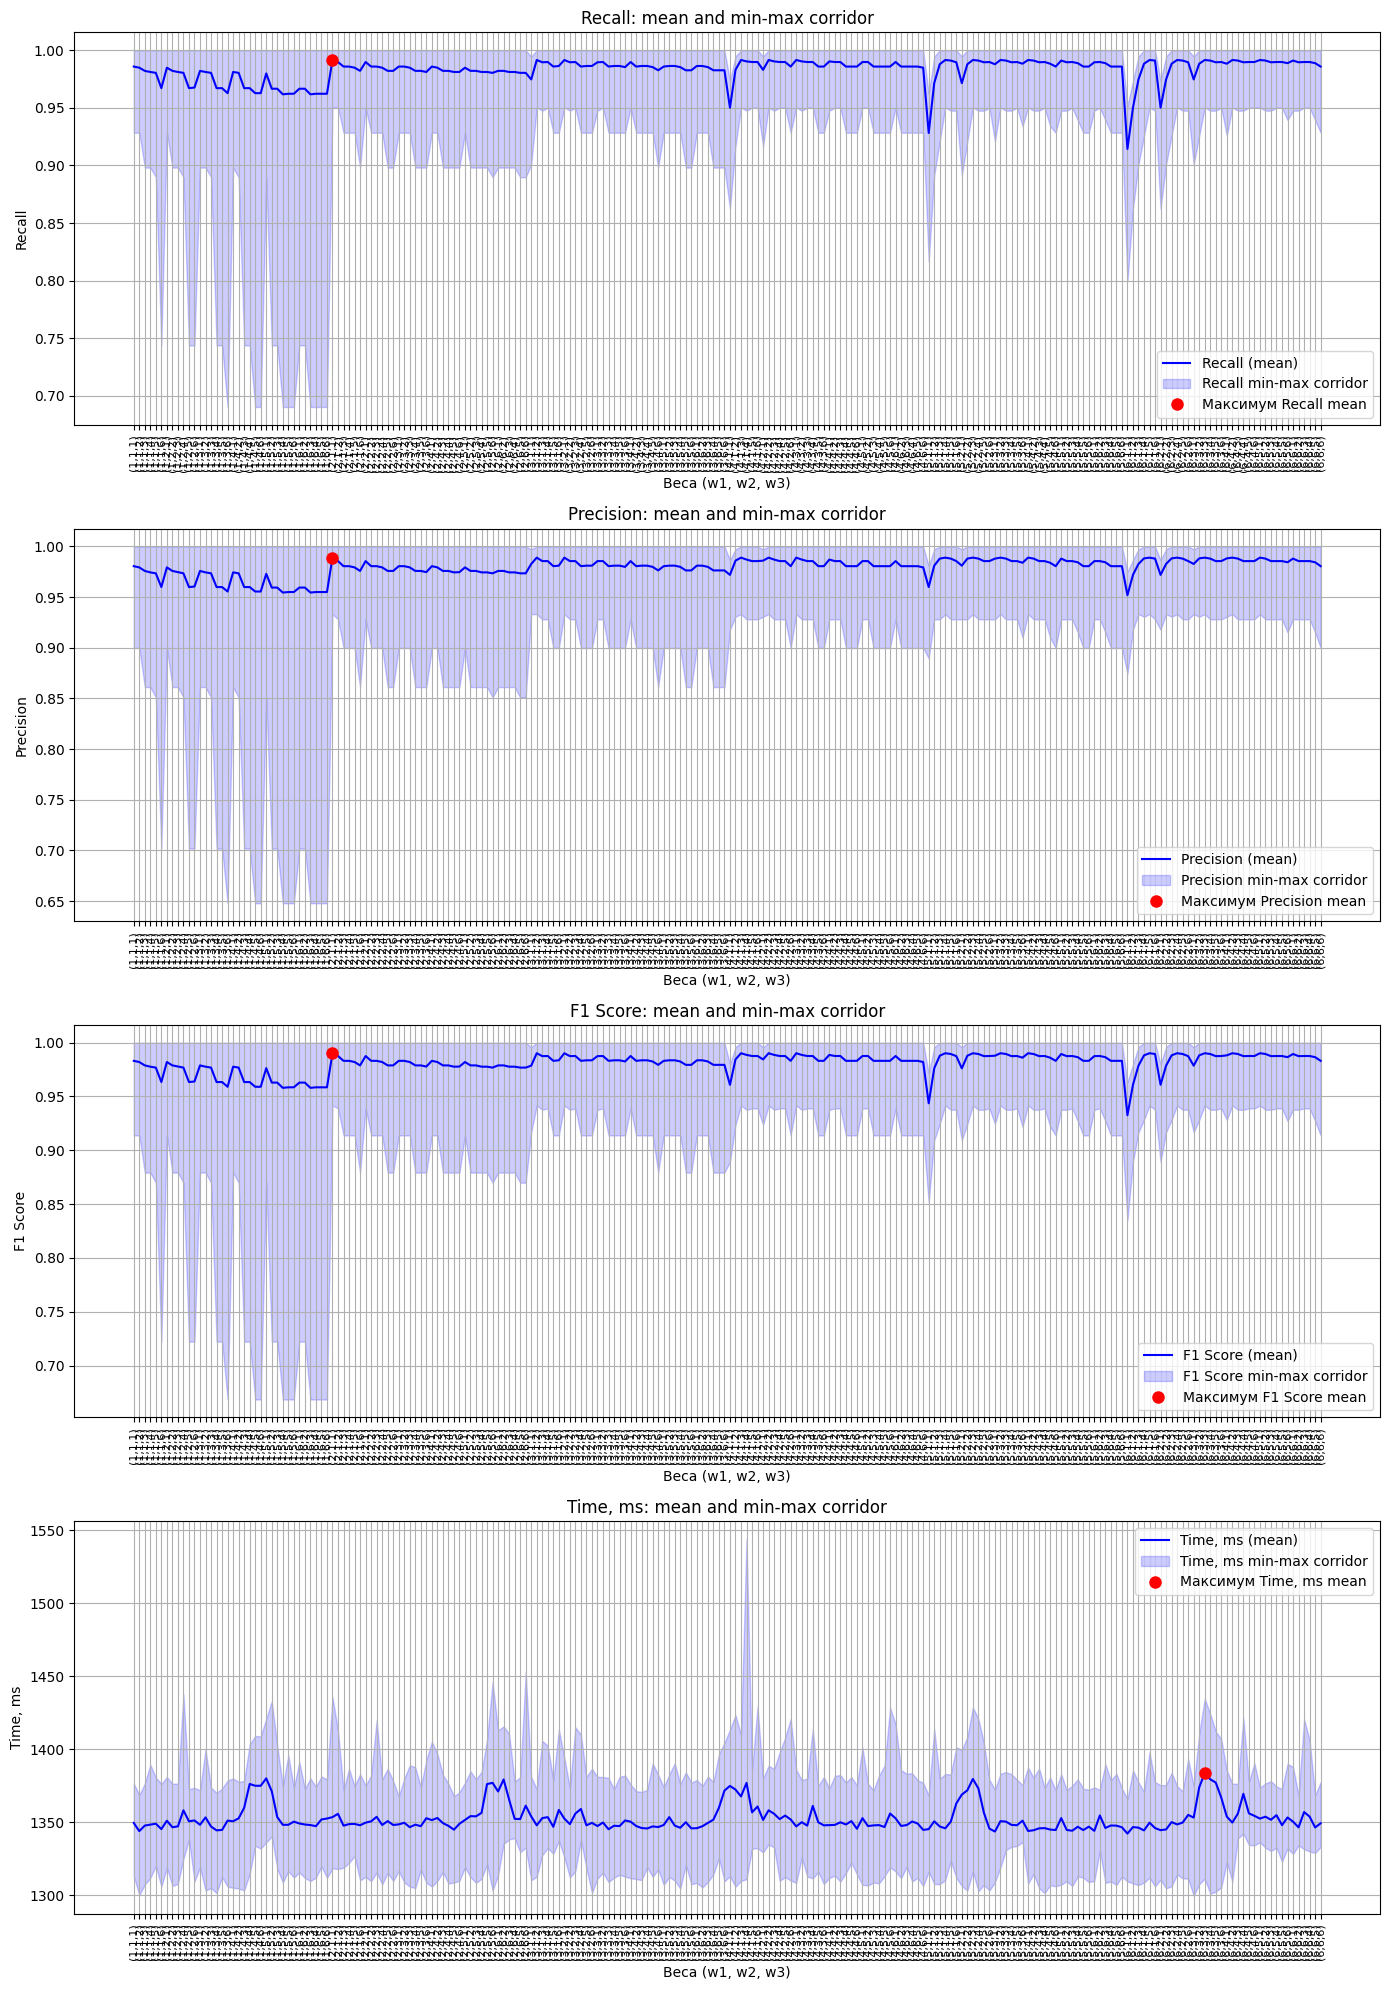

In [98]:
df_lev_nested = optimize_weights(algo_name='levenshtein_nested', diapazon=DIAPAZON)
texts_metrics(df_lev_nested)
_, weights_stats_df_full_df_lev_nested = best_params(df_lev_nested)
weights_stats_df_full_df_lev_nested.head()
plot_metrics(weights_stats_df_full_df_lev_nested)

# Lev V2

Текст: GB
  Среднее значение F1 Score: 0.992163
  Медианное значение F1 Score: 0.991713
  Минимальное значение F1 Score: 0.931174
  Максимальное значение F1 Score: 0.995862
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=2, w2=1, w3=1

Текст: GB2
  Среднее значение F1 Score: 0.998759
  Медианное значение F1 Score: 1.000000
  Минимальное значение F1 Score: 0.934783
  Максимальное значение F1 Score: 1.000000
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1, w2=1, w3=1

Текст: IV13
  Среднее значение F1 Score: 0.991817
  Медианное значение F1 Score: 0.991690
  Минимальное значение F1 Score: 0.942935
  Максимальное значение F1 Score: 0.995851
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=2, w2=1, w3=1

Текст: IV605
  Среднее значение F1 Score: 0.998280
  Медианное значение F1 Score: 1.000000
  Минимальное значение F1 Score: 0.950820
  Максимальное значение F1 Score: 1.000000
  Веса (w1, w2, w3), соответствующие максимальному F1 Score: w1=1

,w1,w2,w3,Recall_min,Recall_max,Recall_mean,Precision_min,Precision_max,Precision_mean,F1_min,F1_max,F1_mean,Time_min_ms,Time_max_ms,Time_mean_ms
0,1,1,1,0.979003,1.0,0.996097,0.958869,1.0,0.992294,0.968831,1.0,0.994183,1350.685750,1452.878875,1404.363243
1,1,1,2,0.944737,1.0,0.991524,0.925450,1.0,0.987083,0.934994,1.0,0.989290,1356.442083,1462.489792,1396.784046
2,1,1,3,0.926121,1.0,0.987627,0.904884,1.0,0.982556,0.915380,1.0,0.985073,1348.498916,1500.207125,1400.591102
3,1,1,4,0.915567,1.0,0.984938,0.894602,1.0,0.979898,0.904963,1.0,0.982399,1348.584500,1425.682459,1390.744428
4,1,1,5,0.890957,1.0,0.980507,0.863753,1.0,0.974930,0.877144,1.0,0.977691,1348.144000,1421.454458,1396.973087


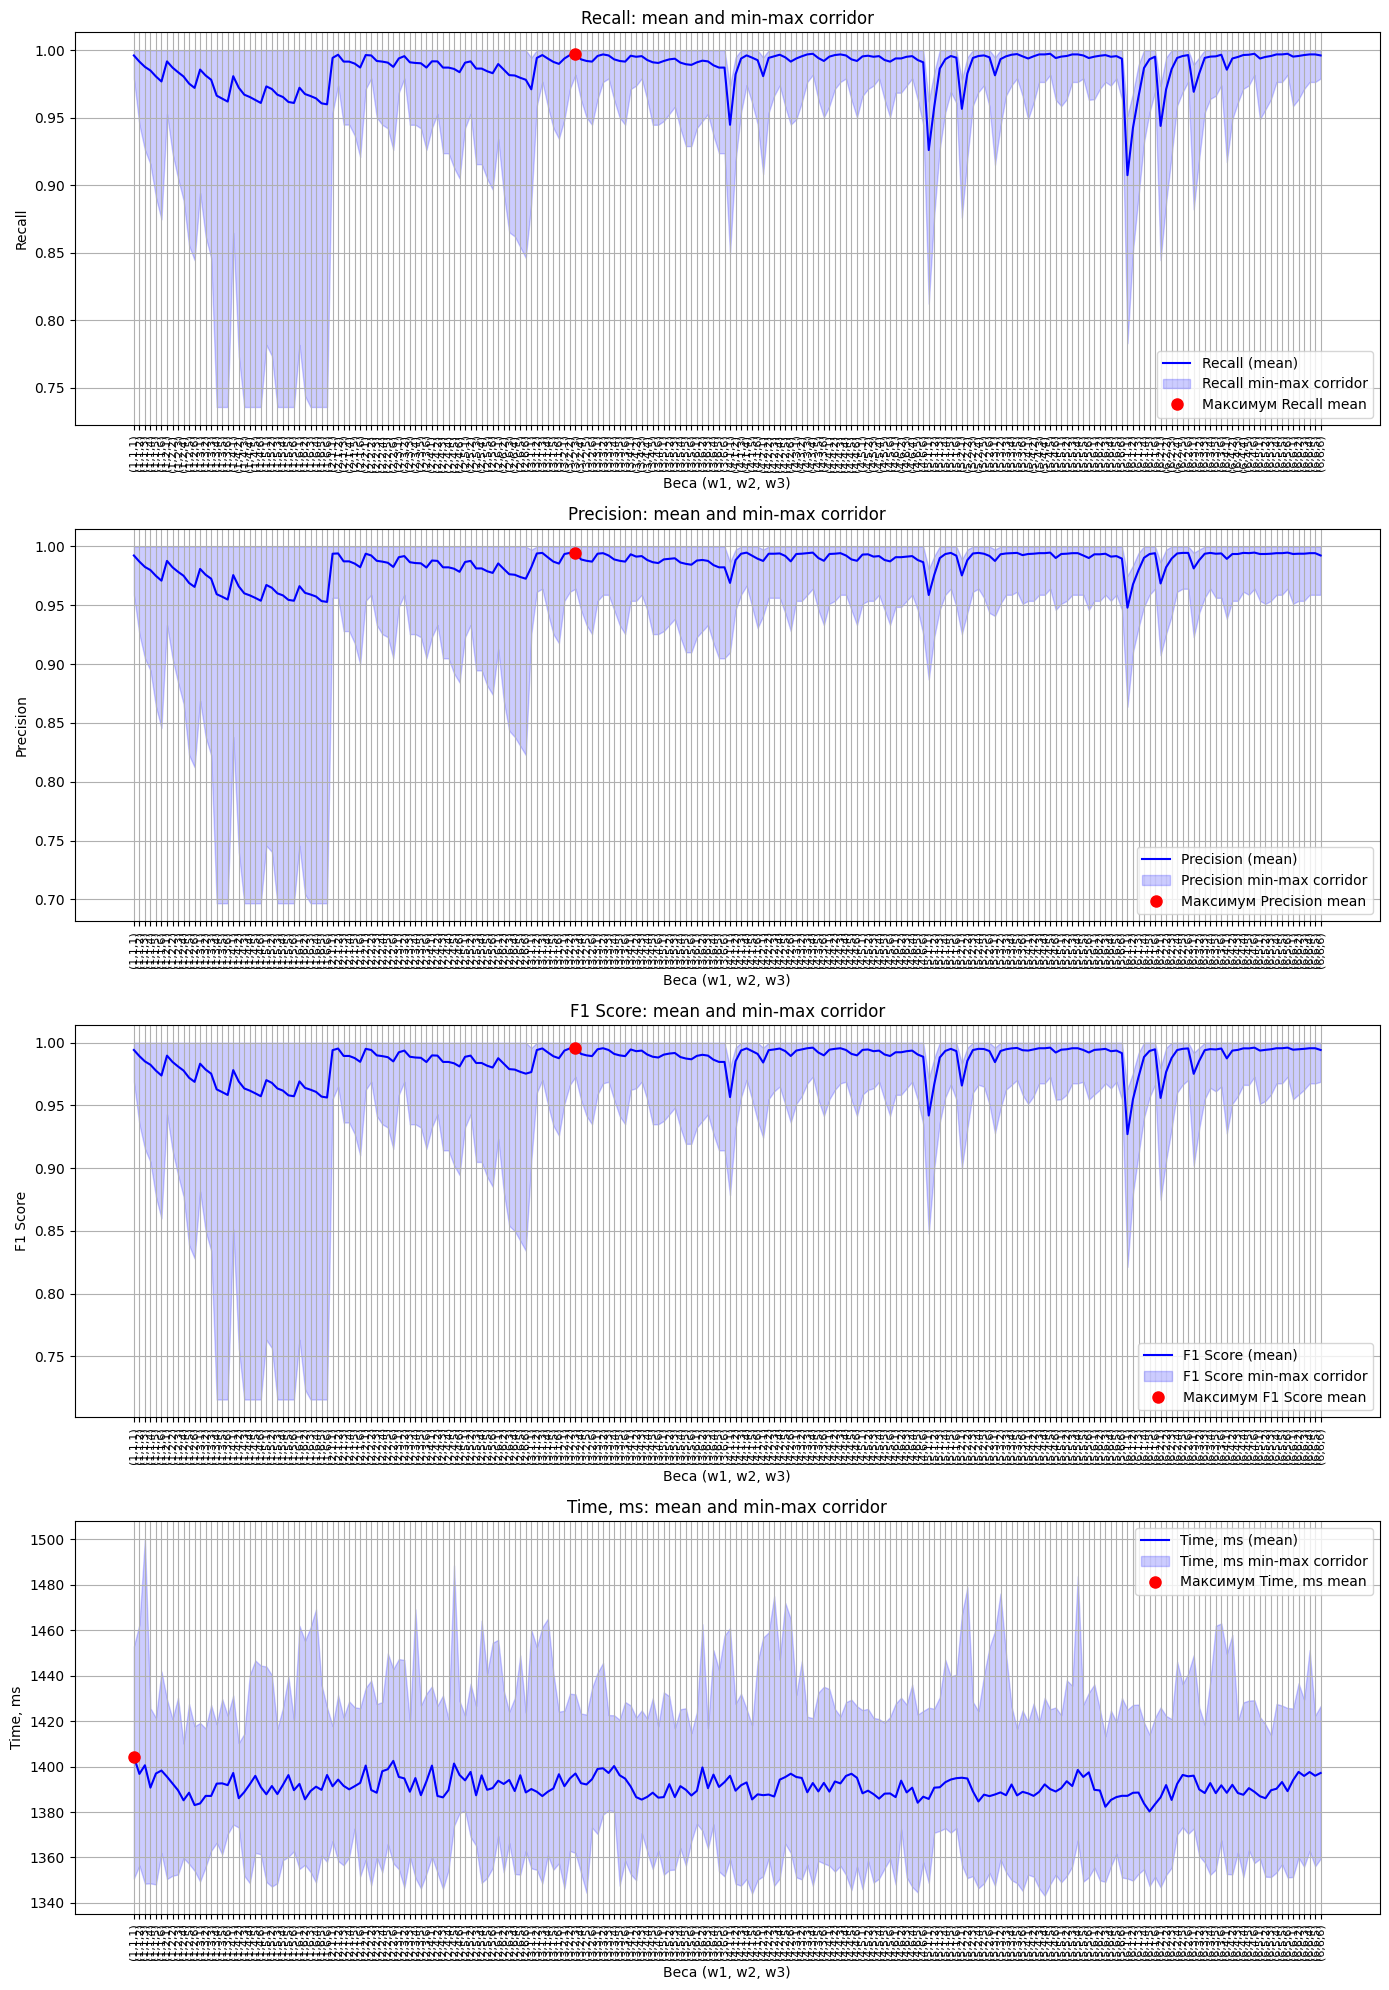

In [103]:
df_lev_v2 = optimize_weights(algo_name='levenshtein_v2', diapazon=DIAPAZON)
texts_metrics(df_lev_v2)
_, weights_stats_df_full_df_lev_v2 = best_params(df_lev_v2)
display(weights_stats_df_full_df_lev_v2.head())
plot_metrics(weights_stats_df_full_df_lev_v2)


In [104]:
# .xlsx via pandas only (no `import openpyxl` — Pylance). If ImportError: %pip install openpyxl
import os

_out = "data_m10/saves/weights_stats_df_full_df_lev_v2.xlsx"
os.makedirs(os.path.dirname(_out), exist_ok=True)
weights_stats_df_full_df_lev_v2.to_excel(_out, index=False, engine="openpyxl")
print("wrote", _out)

wrote data_m10/saves/weights_stats_df_full_df_lev_v2.xlsx


# Сравнение алгоритмов

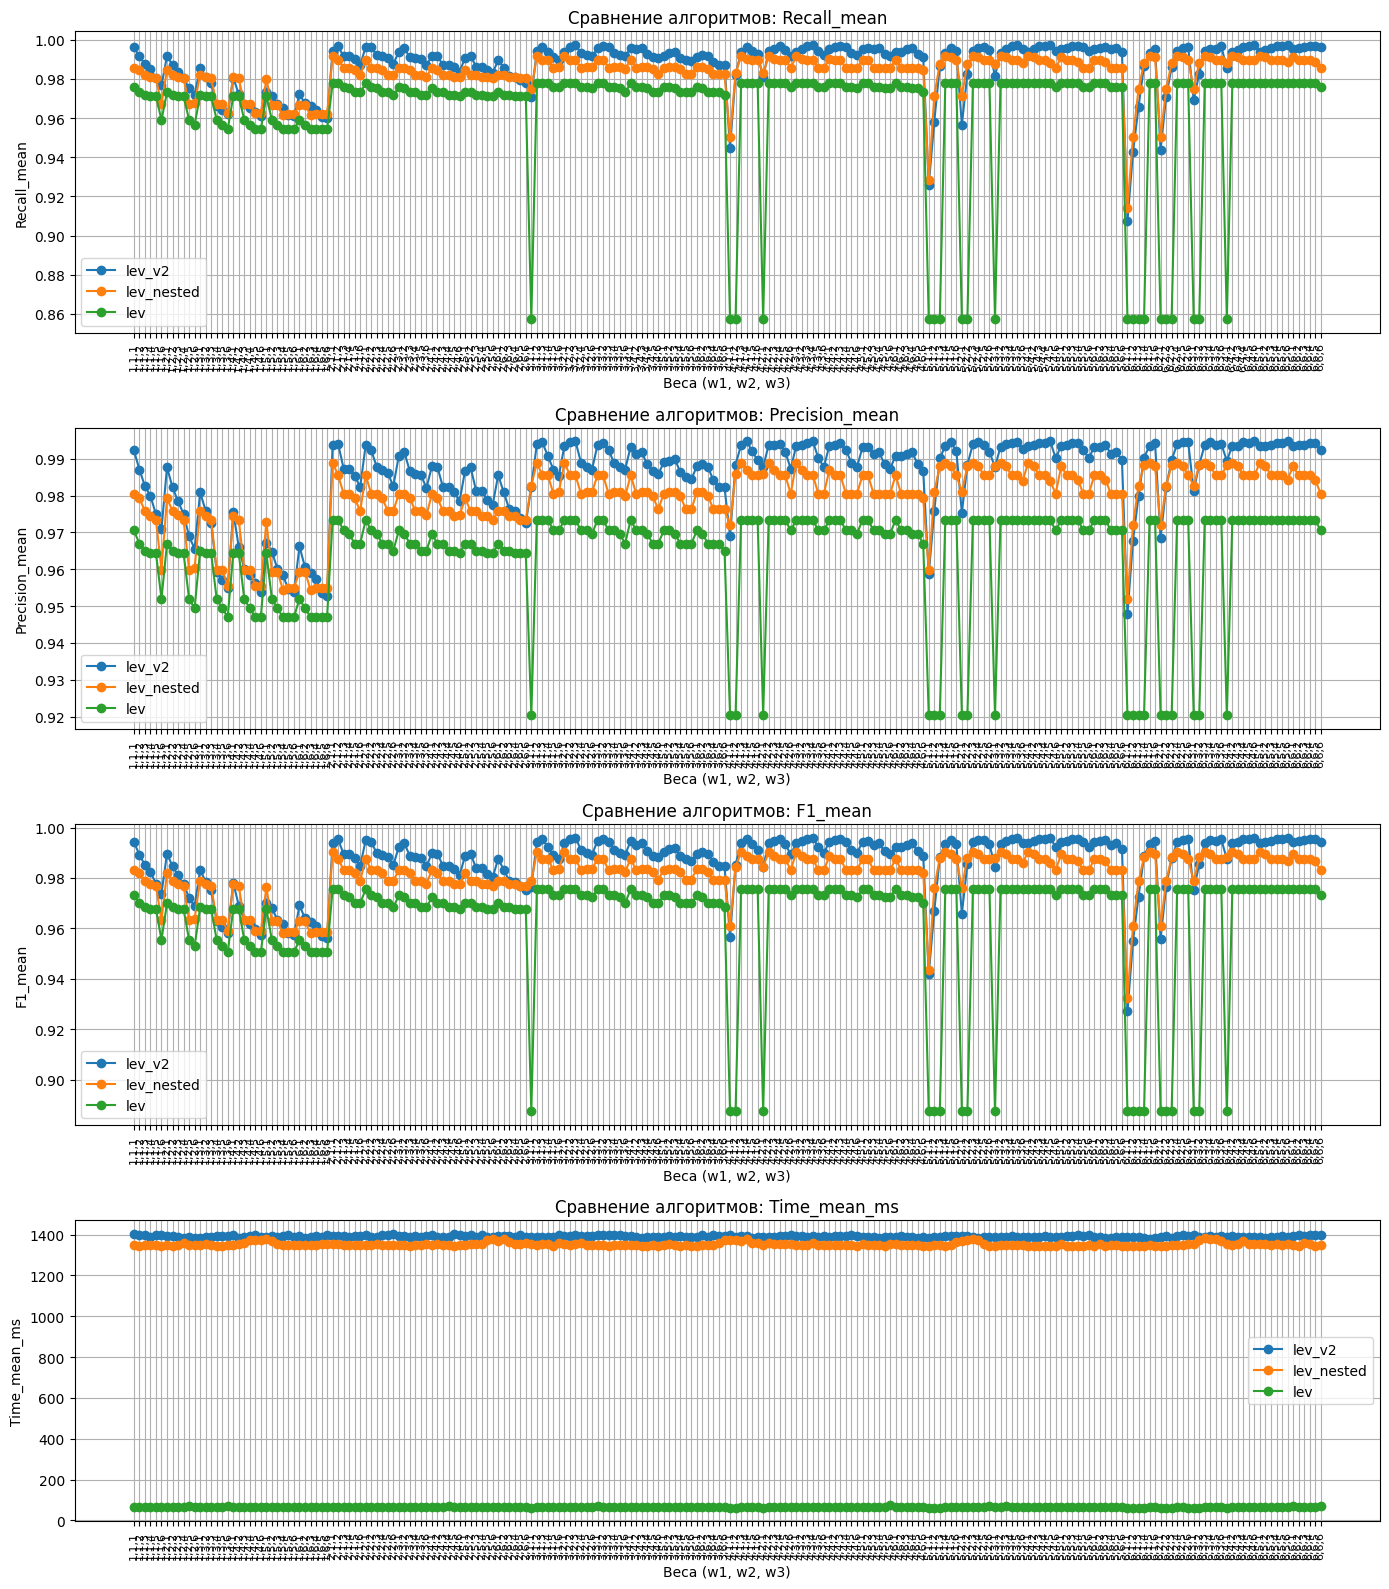

In [105]:
import matplotlib.pyplot as plt

def plot_algorithms_metrics(datasets, algorithm_names, metrics):
    """
    Строит графики сравнения заданных метрик для нескольких алгоритмов (датасетов).
    Каждая линия на графике — это отдельный алгоритм с его весами для соответствующей метрики.
    
    datasets: список датафреймов (weights_stats_df_full_df_lev, weights_stats_df_full_df_lev_v2, ...)
    algorithm_names: список названий алгоритмов (['lev', 'lev_v2', ...])
    metrics: список метрик, которые надо построить (['Recall_mean', 'Precision_mean', ...])
    """
    x_labels = []
    for ds in datasets:
        triples = ds[['w1', 'w2', 'w3']].astype(str).agg(','.join, axis=1)
        x_labels.append(triples.values)
    
    x = [range(len(labels)) for labels in x_labels]
    num_metrics = len(metrics)
    plt.figure(figsize=(14, 4 * num_metrics))
    
    for idx, metric in enumerate(metrics):
        plt.subplot(num_metrics, 1, idx + 1)
        for i, ds in enumerate(datasets):
            plt.plot(x[i], ds[metric], marker='o', label=algorithm_names[i])
        # x ticks сгруппируем по первому датасету
        plt.xticks(x[0], x_labels[0], rotation=90, fontsize=8)
        plt.xlabel("Веса (w1, w2, w3)")
        plt.ylabel(metric)
        plt.title(f"Сравнение алгоритмов: {metric}")
        plt.legend()
        plt.grid(True)
    plt.tight_layout()
    plt.show()

# Пример вызова
datasets = [weights_stats_df_full_df_lev_v2, weights_stats_df_full_df_lev_nested, weights_stats_df_full_df_lev]
algorithm_names = ['lev_v2', 'lev_nested', 'lev']
metrics = ['Recall_mean', 'Precision_mean', 'F1_mean', 'Time_mean_ms']
plot_algorithms_metrics(datasets, algorithm_names, metrics)

In [106]:
# !pip install openpyxl
# import openpyxl

weights_stats_df_full_df_lev_v2.to_excel('/Users/ehlamkin/Desktop/nir_2026_v2/testing/quality/data_m10/saves/weights_stats_df_full_df_lev_v2.xlsx', index=False)
weights_stats_df_full_df_lev_nested.to_excel('/Users/ehlamkin/Desktop/nir_2026_v2/testing/quality/data_m10/saves/weights_stats_df_full_df_lev_nested.xlsx', index=False)
weights_stats_df_full_df_lev.to_excel('/Users/ehlamkin/Desktop/nir_2026_v2/testing/quality/data_m10/saves/weights_stats_df_full_df_lev.xlsx', index=False)

In [8]:
from __future__ import annotations

import re
import time
from collections import defaultdict
from pathlib import Path
from typing import Dict

import docx

from algo.comparison import compare_tokens
from algo.structures import Weights


def _read_docx(path: Path) -> str:
    doc = docx.Document(path)
    return " ".join(p.text for p in doc.paragraphs)


def _tokenize(text: str) -> list[str]:
    return re.findall(r"\S+", text)


def _copy_index_from_name(filename: str) -> int:
    """Последнее число перед .docx — номер копии N."""
    print(filename)
    m = re.search(r"(\d+)\s*\.docx$", filename, flags=re.IGNORECASE)
    if not m:
        raise ValueError(f"Не удалось извлечь номер копии из имени: {filename!r}")
    return int(m.group(1))


def _pair_time_data_files(time_data_dir: Path) -> dict[int, tuple[Path, Path]]:
    files = sorted(time_data_dir.glob("*.docx"))
    if len(files) != 14:
        raise ValueError(f"Ожидалось 14 .docx, найдено {len(files)} в {time_data_dir}")

    by_n: dict[int, list[Path]] = defaultdict(list)
    for p in files:
        by_n[_copy_index_from_name(p.name)].append(p)

    pairs: dict[int, tuple[Path, Path]] = {}
    for n in sorted(by_n.keys()):
        lst = sorted(by_n[n])
        if len(lst) != 2:
            raise ValueError(f"Копия {n}: ожидалось 2 файла, получено {len(lst)}: {[x.name for x in lst]}")
        a, b = lst[0], lst[1]
        a_is_m10 = "m10" in a.stem.lower()
        b_is_m10 = "m10" in b.stem.lower()
        if a_is_m10 and not b_is_m10:
            base, other = a, b
        elif b_is_m10 and not a_is_m10:
            base, other = b, a
        else:
            base, other = (a, b) if a.name <= b.name else (b, a)
        pairs[n] = (base, other)
    return pairs


def benchmark_compare_time_by_m10_token_length(
    algorithm: str,
    algo_weights: Weights,
    time_data_dir: str | Path = "data_m10/time_data",
) -> Dict[int, float]:
    """
    Для каждой пары копий N: сравнение base (M10) vs other.
    Возвращает {число_токенов_M10: время_compare_tokens_мс}.
    """
    root = Path(time_data_dir)
    out: Dict[int, float] = {}
    for _n, (base_path, other_path) in sorted(_pair_time_data_files(root).items()):
        t1_tokens = _tokenize(_read_docx(base_path))
        t2_tokens = _tokenize(_read_docx(other_path))
        key = len(t1_tokens)
        t0 = time.perf_counter()
        compare_tokens(t1_tokens, t2_tokens, algo_weights, algorithm=algorithm)
        ms = (time.perf_counter() - t0) * 1000.0
        out[key] = ms
    return out

In [12]:
lev_times = benchmark_compare_time_by_m10_token_length(
    'levenshtein',
    Weights(1, 1, 1),
    "data_m10/time_data"
)

M10 -- копия 0.docx
M10 — копия 1.docx
M10 — копия 2.docx
M10 — копия 3.docx
M10 — копия 4.docx
M10 — копия 5.docx
M10 — копия 6.docx
МИД181 -- копия 0.docx
МИД181 — копия 1.docx
МИД181 — копия 2.docx
МИД181 — копия 3.docx
МИД181 — копия 4.docx
МИД181 — копия 5.docx
МИД181 — копия 6.docx


In [14]:
lev_nested_times = benchmark_compare_time_by_m10_token_length(
    'levenshtein_nested',
    Weights(1, 1, 1),
    "data_m10/time_data"
)

M10 -- копия 0.docx
M10 — копия 1.docx
M10 — копия 2.docx
M10 — копия 3.docx
M10 — копия 4.docx
M10 — копия 5.docx
M10 — копия 6.docx
МИД181 -- копия 0.docx
МИД181 — копия 1.docx
МИД181 — копия 2.docx
МИД181 — копия 3.docx
МИД181 — копия 4.docx
МИД181 — копия 5.docx
МИД181 — копия 6.docx


In [15]:
lev_v2_times = benchmark_compare_time_by_m10_token_length(
    'levenshtein_v2',
    Weights(1, 1, 1, 1, 1, 1),
    "data_m10/time_data"
)

M10 -- копия 0.docx
M10 — копия 1.docx
M10 — копия 2.docx
M10 — копия 3.docx
M10 — копия 4.docx
M10 — копия 5.docx
M10 — копия 6.docx
МИД181 -- копия 0.docx
МИД181 — копия 1.docx
МИД181 — копия 2.docx
МИД181 — копия 3.docx
МИД181 — копия 4.docx
МИД181 — копия 5.docx
МИД181 — копия 6.docx


In [16]:
lev_times

{359: 79.2731250039651,
 718: 310.02341600105865,
 1077: 700.0415419970523,
 1436: 1284.6415000021807,
 1795: 2020.7539160037413,
 2154: 2916.8037500057835,
 2513: 3963.0929580016527}

In [17]:
lev_nested_times

{359: 1822.7595830030623,
 718: 7167.244208001648,
 1077: 16436.746542000037,
 1436: 29415.50237499905,
 1795: 45187.99612500152,
 2154: 63766.70137500332,
 2513: 87440.42904100206}

In [18]:
lev_v2_times

{359: 1830.7302499961224,
 718: 7240.365625002596,
 1077: 16973.773124998843,
 1436: 29634.071458000108,
 1795: 46049.930749999476,
 2154: 66523.86662500066,
 2513: 89752.73654200282}

In [27]:
import matplotlib.pyplot as plt
import numpy as np

def plot_multiple_dicts(dicts, names=None, xlabel='Количество слов', ylabel='Время, мс', title='График зависимости времени работы алгоритмов от числа слов'):
    """
    Функция для построения графиков зависимости значений от ключей для нескольких словарей,
    а также графика покомпонентной разницы между первым и вторым словарём (если есть два).
    Второй график — на логарифмической оси y.
    """
    fig, axs = plt.subplots(2, 1, figsize=(8,10))
    
    # Первый сабплот — обычные графики по данным
    for i, d in enumerate(dicts):
        x = list(d.keys())
        y = list(d.values())
        if names and i < len(names):
            axs[0].plot(x, y, marker='o', label=names[i])
        else:
            axs[0].plot(x, y, marker='o')
    axs[0].set_xlabel(xlabel)
    axs[0].set_ylabel(ylabel)
    axs[0].set_title(title)
    axs[0].grid(True)
    if names:
        axs[0].legend()
    
    # Второй сабплот — логарифмическая ось y, покомпонентная разница (только если два элемента)
    if len(dicts) >= 2:
        d1 = dicts[0]
        d2 = dicts[1]
        # Общие ключи
        keys = list(sorted(set(d1.keys()) & set(d2.keys())))
        diffs = [d2[k] - d1[k] for k in keys]
        axs[1].plot(keys, diffs, marker='o', label='Diff (2nd - 1st)')
        axs[1].set_xlabel(xlabel)
        axs[1].set_ylabel('Разница')
        axs[1].set_title('Покомпонентная разница (лог. ось Y)')
        axs[1].set_yscale('log')
        axs[1].grid(True)
        axs[1].legend()
    else:
        axs[1].set_visible(False)
    
    plt.tight_layout()
    plt.show()

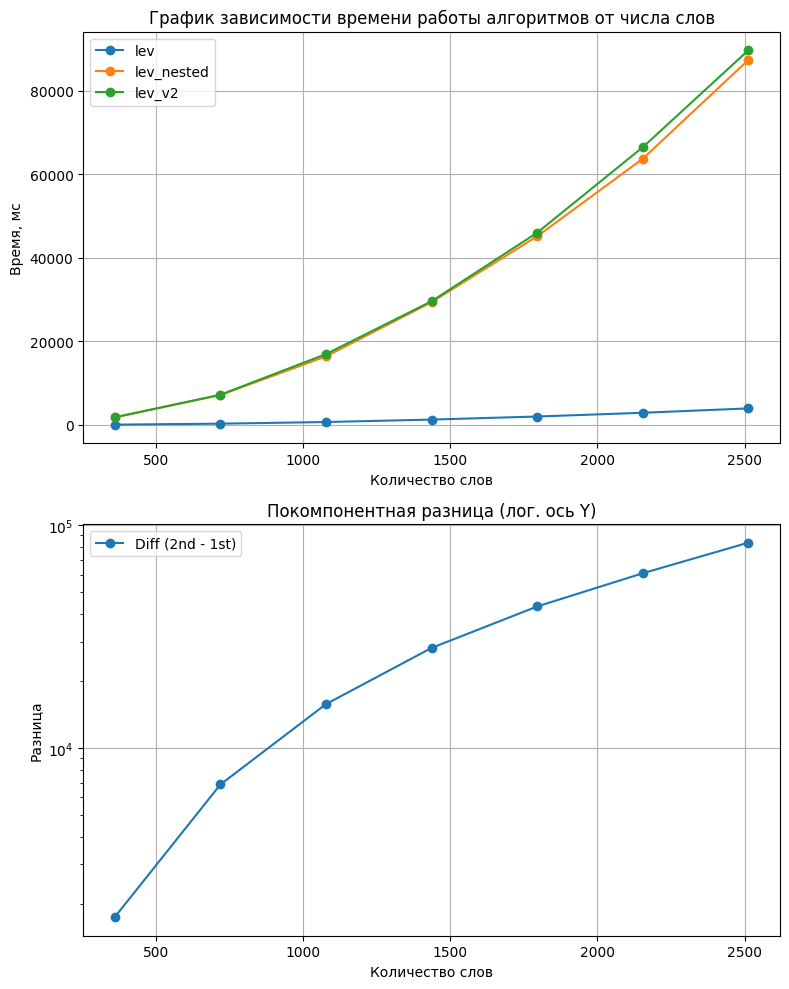

In [28]:
plot_multiple_dicts([lev_times, lev_nested_times, lev_v2_times], ['lev', 'lev_nested', 'lev_v2'])

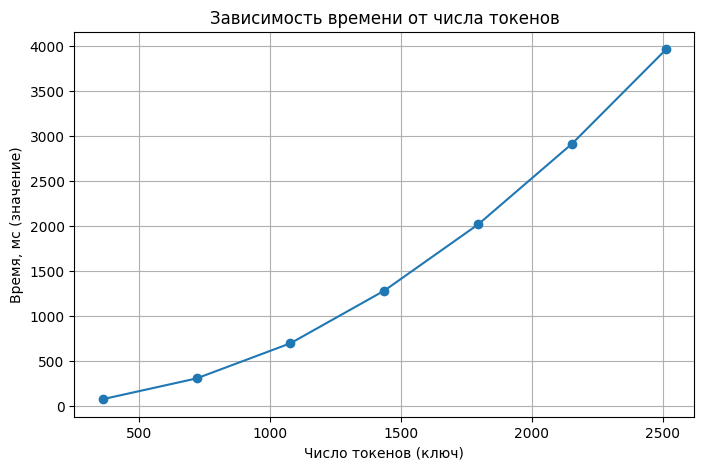

In [25]:
import matplotlib.pyplot as plt

data = {
    359: 1854.685165999399,
    718: 7433.71583300177,
    1077: 16692.44187499862,
    1436: 29182.600625004852,
    1795: 46253.47904099908,
    2154: 65926.42179199902,
    2513: 89735.946666995
}

x = list(lev_times.keys())
y = list(lev_times.values())

plt.figure(figsize=(8,5))
plt.plot(x, y, marker='o')
plt.xlabel('Число токенов (ключ)')
plt.ylabel('Время, мс (значение)')
plt.title('Зависимость времени от числа токенов')
plt.grid(True)
plt.show()

In [ ]:
Построй квадратичную интерполяцию MSE по данным